# BreastMNIST with PyTorch

## Goal

Can a small convolutional neural network (CNN) rank malignant breast ultrasound images above the combined normal and benign class better than a linear model?

The saved CPU run gave test ROC AUC of **0.824 for logistic regression** and **0.799 for the CNN**. The CNN recorded slightly higher average precision (0.660 vs. 0.641).

Work through one section at a time. Start with setup and data inspection, then come back for the baselines and CNN. Run the test section after you freeze the model choices. Use the prompts to write a short lab note in your own words.

This is an educational benchmark. BreastMNIST has 780 downsampled grayscale images from the Breast Ultrasound Images (BUSI) dataset. We use the official split of 546 training, 78 validation, and 156 test images at 28 × 28 pixels. The official labels are `0 = malignant` and `1 = normal or benign`. We remap them so the positive class for our metrics is malignant.

[MedMNIST v2 paper](https://doi.org/10.1038/s41597-022-01721-8) · [Official data and license](https://zenodo.org/records/10519652) · [Original BUSI paper](https://doi.org/10.1016/j.dib.2019.104863)

## 1. Set up Colab

To reproduce the saved experiment, upload this notebook in [Google Colab](https://colab.research.google.com/), click **Connect**, and choose **Runtime → Run all**. A hosted CPU is enough. The run below uses a fixed configuration and the official split. You can also work through the sections one by one and use the practice prompts.

In [1]:
from copy import deepcopy
import hashlib
from pathlib import Path
import platform
import random
from urllib.request import urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 0.001
THRESHOLD = 0.5
IMAGE_SIZE = 28
EXPECTED_COUNTS = {"train": 546, "val": 78, "test": 156}
CLASS_NAMES = ["Normal or benign", "Malignant"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if device.type == "cpu":
    torch.set_num_threads(1)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 110,
})
BLUE, ORANGE, GRAY = "#255e91", "#a84e1e", "#5b6470"

print(f"Python {platform.python_version()} | Device: {device} | Seed: {SEED}")
print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__}")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.14.6 | Device: cpu | Seed: 42
PyTorch 2.15.0 | scikit-learn 1.9.0
NumPy 2.4.6 | pandas 3.0.3 | Matplotlib 3.11.0


## 2. Download and inspect the data

The cell downloads the official archive to the runtime and verifies its checksum. Use training images to see what the model receives. Validation images guide model selection. We load the test arrays in section 6.

In [2]:
DATA_URL = "https://zenodo.org/records/10519652/files/breastmnist.npz?download=1"
DATA_MD5 = "750601b1f35ba3300ea97c75c52ff8f6"
data_path = Path("data/breastmnist.npz")

if not data_path.exists() or hashlib.md5(data_path.read_bytes()).hexdigest() != DATA_MD5:
    with urlopen(DATA_URL, timeout=60) as response:
        archive = response.read()
    if hashlib.md5(archive).hexdigest() != DATA_MD5:
        raise ValueError("Download checksum mismatch. Retry the official download.")
    data_path.parent.mkdir(exist_ok=True)
    data_path.write_bytes(archive)


def load_split(split):
    with np.load(data_path, allow_pickle=False) as data:
        images = data[f"{split}_images"]
        official_labels = data[f"{split}_labels"].reshape(-1)

    expected_count = EXPECTED_COUNTS[split]
    assert images.shape == (expected_count, IMAGE_SIZE, IMAGE_SIZE)
    assert images.dtype == np.uint8
    assert official_labels.shape == (expected_count,)
    assert np.array_equal(np.unique(official_labels), [0, 1])

    malignant_labels = (official_labels == 0).astype(np.int64)
    return images, malignant_labels


train_images, train_labels = load_split("train")
val_images, val_labels = load_split("val")

split_counts = pd.DataFrame(
    [np.bincount(labels, minlength=2) for labels in (train_labels, val_labels)],
    index=["Train", "Validation"],
    columns=CLASS_NAMES,
)
split_counts["Total"] = split_counts.sum(axis=1)
display(split_counts)

,Normal or benign,Malignant,Total
Train,399,147,546
Validation,57,21,78


### Look at both classes

Each panel shows the pixel grid given to the model. Take a moment to record the class balance and which details you find hard to see after downsampling.

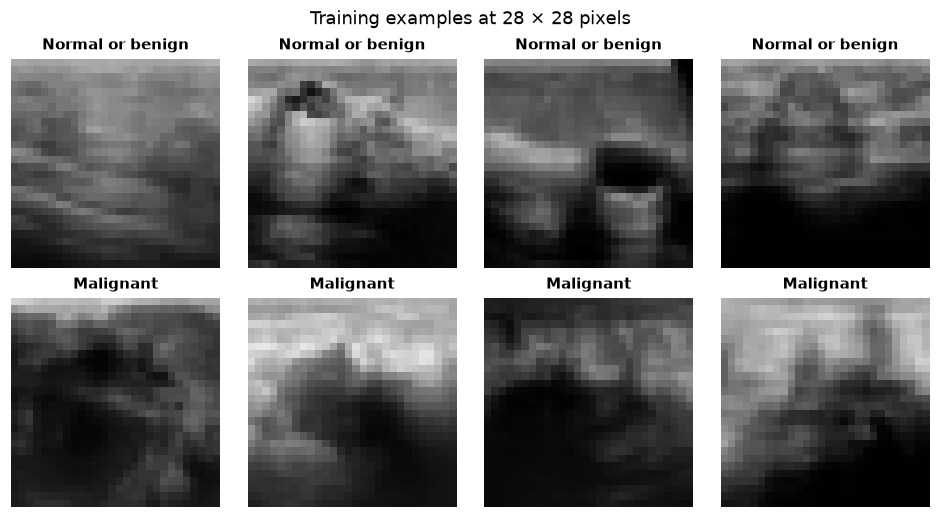

In [3]:
sample_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(8.6, 4.6), layout="constrained")
fig.suptitle("Training examples at 28 × 28 pixels")
for label, row in enumerate(axes):
    indices = sample_rng.choice(np.flatnonzero(train_labels == label), size=4, replace=False)
    for axis, index in zip(row, indices):
        axis.imshow(train_images[index], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axis.set_title(CLASS_NAMES[label], fontsize=10)
        axis.set_axis_off()
plt.show()

**Checkpoint.** Calculate the accuracy you would get by always predicting the more common training class. What would its malignant sensitivity be on a split containing both classes? Write your prediction before running the next section.

## 3. Establish two baselines

The majority baseline predicts the most common training class for every image. Its score is the same training-set prevalence for every image, so it cannot rank cases. Logistic regression learns a weighted sum of the 784 pixel intensities. It gives the CNN a stronger comparison because both models see the same input.

In [4]:
def flat_pixels(images):
    return images.reshape(len(images), -1).astype(np.float32) / 255.0


def summarize_scores(labels, scores):
    predictions = (scores >= THRESHOLD).astype(int)
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()
    return {
        "ROC AUC": roc_auc_score(labels, scores),
        "Average precision": average_precision_score(labels, scores),
        "Accuracy": accuracy_score(labels, predictions),
        "Balanced accuracy": balanced_accuracy_score(labels, predictions),
        "Malignant sensitivity": true_positive / (true_positive + false_negative),
        "Specificity": true_negative / (true_negative + false_positive),
    }


train_prevalence = train_labels.mean()
linear_model = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
linear_model.fit(flat_pixels(train_images), train_labels)

validation_scores = {
    "Majority class": np.full(len(val_labels), train_prevalence),
    "Logistic regression": linear_model.predict_proba(flat_pixels(val_images))[:, 1],
}
display(pd.DataFrame({
    name: summarize_scores(val_labels, scores)
    for name, scores in validation_scores.items()
}).T.round(3))

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Malignant sensitivity,Specificity
Majority class,0.500,0.269,0.731,0.500,0.000,1.000
Logistic regression,0.844,0.788,0.833,0.721,0.476,0.965


## 4. Build a small CNN

We scale pixels to `[0, 1]` in both learned models. The CNN input has shape `[batch, 1, height, width]`. Convolutions learn local patterns and max pooling reduces the spatial dimensions twice. The last layer emits one logit per image. `BCEWithLogitsLoss` takes that raw logit and a binary target. During evaluation, sigmoid maps the logit to a score between zero and one. [PyTorch loss documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)

Before running the cells, predict the feature-map shape after each max-pooling layer for an input of `[32, 1, 28, 28]`.

In [5]:
def make_loader(images, labels, *, shuffle=False):
    inputs = torch.from_numpy(images).float().unsqueeze(1) / 255.0
    targets = torch.from_numpy(labels).float()
    return DataLoader(
        TensorDataset(inputs, targets),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )


def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * (IMAGE_SIZE // 4) ** 2, 1),
    )


train_loader = make_loader(train_images, train_labels, shuffle=True)
val_loader = make_loader(val_images, val_labels)
torch.manual_seed(SEED)
cnn = make_cnn().to(device)

batch_images, batch_labels = next(iter(val_loader))
with torch.inference_mode():
    activations = batch_images.to(device)
    for layer in cnn:
        activations = layer(activations)
        if isinstance(layer, nn.MaxPool2d):
            print(f"After max pooling: {tuple(activations.shape)}")
    assert activations.squeeze(1).shape == batch_labels.shape
print(f"Input: {tuple(batch_images.shape)} | Raw CNN output: {tuple(activations.shape)}")

After max pooling: (32, 16, 14, 14)
After max pooling: (32, 32, 7, 7)
Input: (32, 1, 28, 28) | Raw CNN output: (32, 1)


## 5. Train and choose a checkpoint

Each training batch makes predictions, computes loss, backpropagates, and updates the weights. The validation loop collects scores without updating weights. We keep the epoch with the highest validation ROC AUC, taking the earliest in a tie. Loss measures the quality of the predicted scores under the training objective. ROC AUC measures ranking across thresholds.

**Practice.** Before moving to the test, compare the CNN and logistic regression on validation. Pick which model you would lead with and write down why. If you experiment with the CNN, keep the official splits and record what you changed.

In [6]:
loss_function = nn.BCEWithLogitsLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images).squeeze(1)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
    return total_loss / len(loader.dataset)


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    score_batches = []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images).squeeze(1)
        total_loss += loss_function(logits, labels).item() * len(labels)
        score_batches.append(torch.sigmoid(logits).cpu().numpy())
    return total_loss / len(loader.dataset), np.concatenate(score_batches)

In [7]:
torch.manual_seed(SEED)
cnn = make_cnn().to(device)
train_loader = make_loader(train_images, train_labels, shuffle=True)
optimizer = torch.optim.Adam(cnn.parameters(), lr=LEARNING_RATE)
best_auc = -np.inf
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(cnn, train_loader, optimizer)
    val_loss, val_scores = evaluate(cnn, val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    history.append((epoch, train_loss, val_loss, val_auc))
    if val_auc > best_auc:
        best_auc = val_auc
        best_epoch = epoch
        best_weights = deepcopy(cnn.state_dict())

cnn.load_state_dict(best_weights)
_, validation_scores["Small CNN"] = evaluate(cnn, val_loader)
curves = pd.DataFrame(history, columns=["Epoch", "Train loss", "Validation loss", "ROC AUC"])
print(f"Selected epoch {best_epoch:02d} | Validation ROC AUC {best_auc:.3f}")
display(pd.DataFrame({
    name: summarize_scores(val_labels, scores)
    for name, scores in validation_scores.items()
}).T.round(3))

Selected epoch 14 | Validation ROC AUC 0.795


,ROC AUC,Average precision,Accuracy,Balanced accuracy,Malignant sensitivity,Specificity
Majority class,0.500,0.269,0.731,0.500,0.000,1.000
Logistic regression,0.844,0.788,0.833,0.721,0.476,0.965
Small CNN,0.795,0.712,0.821,0.667,0.333,1.000


### Read the learning curves

Look for a widening gap between training and validation loss. Record where it starts, if present, and whether it coincides with a plateau or decline in validation AUC.

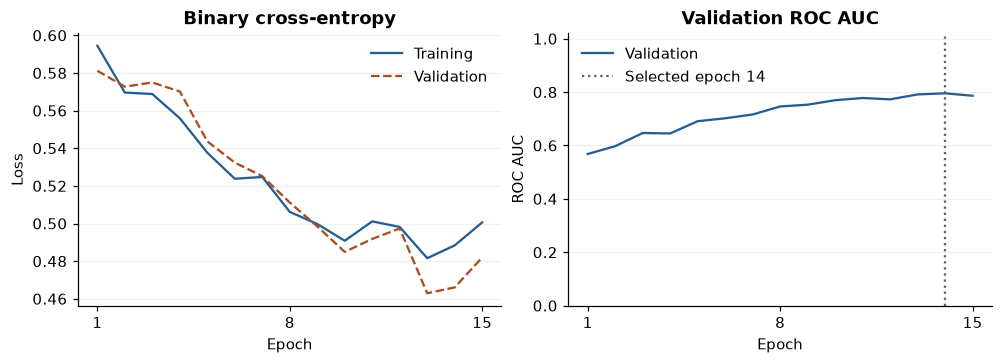

In [8]:
fig, (loss_axis, auc_axis) = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
loss_axis.plot(curves["Epoch"], curves["Train loss"], color=BLUE, label="Training")
loss_axis.plot(curves["Epoch"], curves["Validation loss"], color=ORANGE, linestyle="--", label="Validation")
loss_axis.set(title="Binary cross-entropy", xlabel="Epoch", ylabel="Loss")
loss_axis.legend(frameon=False)

auc_axis.plot(curves["Epoch"], curves["ROC AUC"], color=BLUE, label="Validation")
auc_axis.axvline(best_epoch, color=GRAY, linestyle=":", label=f"Selected epoch {best_epoch}")
auc_axis.set(title="Validation ROC AUC", xlabel="Epoch", ylabel="ROC AUC", ylim=(0, 1.02))
auc_axis.legend(frameon=False)
for axis in (loss_axis, auc_axis):
    axis.set_xticks(sorted({1, (EPOCHS + 1) // 2, EPOCHS}))
    axis.grid(axis="y", alpha=0.2)
plt.show()
training_figure = fig

## 6. Evaluate the frozen models on the test set

Record your final architecture, checkpoint rule, and threshold before running this section. The threshold of 0.5 is fixed for this exercise. If you later tune a threshold or model in response to these test results, treat the follow-up as exploratory and use fresh held-out data for confirmation.

ROC AUC measures how well scores rank malignant above nonmalignant images. Average precision summarizes the precision–recall curve and is sensitive to class prevalence. Sensitivity is the fraction of malignant images flagged. Specificity is the fraction of normal or benign images correctly classified. Balanced accuracy averages sensitivity and specificity.

In [9]:
test_images, test_labels = load_split("test")
_, cnn_test_scores = evaluate(cnn, make_loader(test_images, test_labels))
test_scores = {
    "Majority class": np.full(len(test_labels), train_prevalence),
    "Logistic regression": linear_model.predict_proba(flat_pixels(test_images))[:, 1],
    "Small CNN": cnn_test_scores,
}
test_results = pd.DataFrame({
    name: summarize_scores(test_labels, scores)
    for name, scores in test_scores.items()
}).T
print(f"Test set: {len(test_labels)} images | Malignant: {test_labels.sum()} | Threshold: {THRESHOLD}")
display(test_results.round(3))

Test set: 156 images | Malignant: 42 | Threshold: 0.5


,ROC AUC,Average precision,Accuracy,Balanced accuracy,Malignant sensitivity,Specificity
Majority class,0.500,0.269,0.731,0.500,0.000,1.000
Logistic regression,0.824,0.641,0.795,0.679,0.429,0.930
Small CNN,0.799,0.660,0.769,0.586,0.190,0.982


### Compare the rankings and inspect CNN errors

The horizontal line in the precision–recall plot shows the malignant prevalence in the test set. The confusion matrix uses the fixed threshold. Its bottom-left cell counts malignant images predicted as normal or benign.

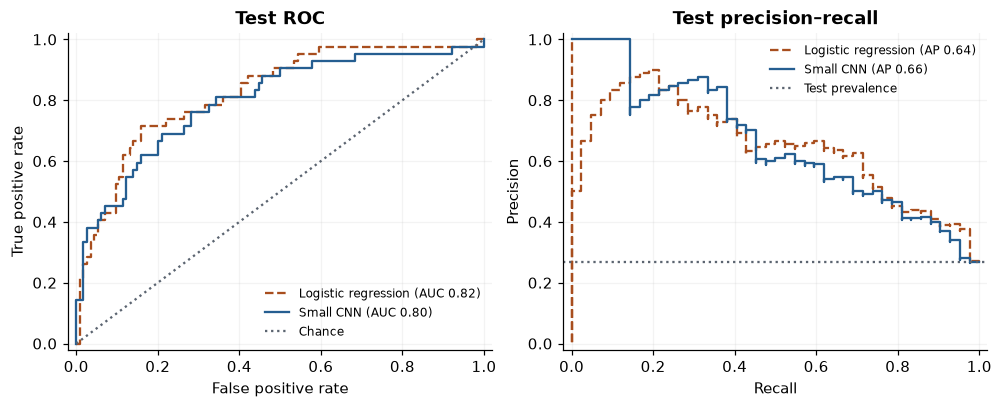

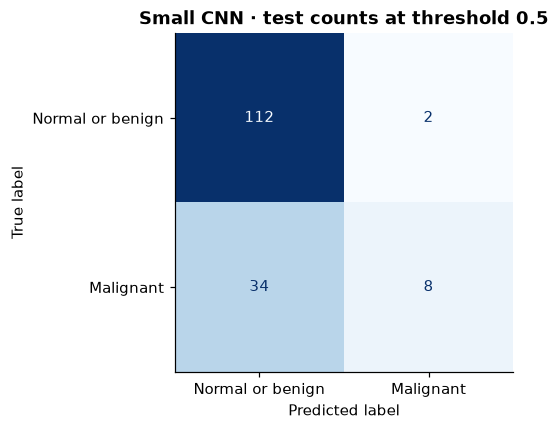

In [10]:
fig, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
for name, color, style in [
    ("Logistic regression", ORANGE, "--"),
    ("Small CNN", BLUE, "-"),
]:
    scores = test_scores[name]
    false_positive_rate, true_positive_rate, _ = roc_curve(test_labels, scores)
    precision, recall, _ = precision_recall_curve(test_labels, scores)
    auc = test_results.loc[name, "ROC AUC"]
    ap = test_results.loc[name, "Average precision"]
    roc_axis.plot(
        false_positive_rate, true_positive_rate, color=color,
        linestyle=style, label=f"{name} (AUC {auc:.2f})",
    )
    pr_axis.step(
        recall, precision, where="post", color=color,
        linestyle=style, label=f"{name} (AP {ap:.2f})",
    )

roc_axis.plot([0, 1], [0, 1], color=GRAY, linestyle=":", label="Chance")
pr_axis.axhline(test_labels.mean(), color=GRAY, linestyle=":", label="Test prevalence")
roc_axis.set(title="Test ROC", xlabel="False positive rate", ylabel="True positive rate")
pr_axis.set(title="Test precision–recall", xlabel="Recall", ylabel="Precision")
for axis in (roc_axis, pr_axis):
    axis.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    axis.grid(alpha=0.15)
    axis.legend(frameon=False, fontsize=8)
plt.show()
test_curve_figure = fig

cnn_predictions = (cnn_test_scores >= THRESHOLD).astype(int)
fig, axis = plt.subplots(figsize=(5.7, 3.8), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    test_labels, cnn_predictions, labels=[0, 1], display_labels=CLASS_NAMES,
    colorbar=False, cmap="Blues", values_format="d", ax=axis,
)
axis.set_title(f"Small CNN · test counts at threshold {THRESHOLD}")
plt.show()
confusion_figure = fig

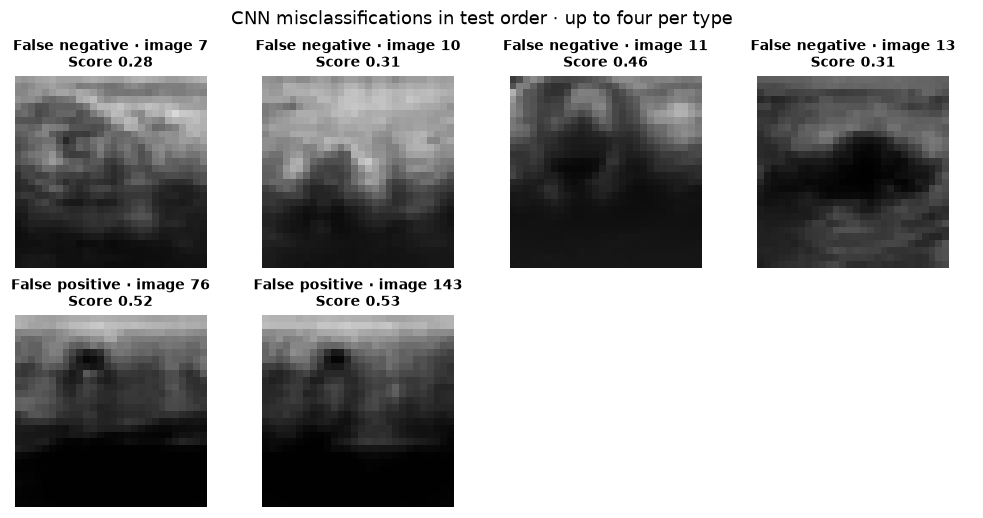

In [11]:
false_negatives = np.flatnonzero((test_labels == 1) & (cnn_predictions == 0))
false_positives = np.flatnonzero((test_labels == 0) & (cnn_predictions == 1))

fig, axes = plt.subplots(2, 4, figsize=(9, 4.6), layout="constrained")
fig.suptitle("CNN misclassifications in test order · up to four per type")
for row, short_name, errors in zip(
    axes, ("False negative", "False positive"), (false_negatives, false_positives)
):
    for axis in row:
        axis.set_axis_off()
    if len(errors) == 0:
        row[0].text(0.5, 0.5, f"No {short_name.lower()}s", ha="center", va="center")
    for axis, index in zip(row, errors[:4]):
        axis.imshow(test_images[index], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axis.set_title(f"{short_name} · image {index}\nScore {cnn_test_scores[index]:.2f}", fontsize=9)
plt.show()

### Audit exact matches across splits

Compare the stored pixel arrays. An exact match shows that the same 28 × 28 input reaches the model in two splits. Exact matching cannot find similar scans or establish patient identity. The main results above keep the official split for comparability.

In [12]:
def index_by_pixels(images):
    indices = {}
    for index, image in enumerate(images):
        indices.setdefault(image.tobytes(), []).append(index)
    return indices


splits = {
    "train": (train_images, train_labels),
    "val": (val_images, val_labels),
    "test": (test_images, test_labels),
}
pixel_indices = {name: index_by_pixels(images) for name, (images, _) in splits.items()}
for first, second in (("train", "val"), ("train", "test"), ("val", "test")):
    shared_pixels = pixel_indices[first].keys() & pixel_indices[second].keys()
    print(f"{first} / {second}: {len(shared_pixels)} distinct exact matches")
    for pixels in sorted(shared_pixels):
        for split in (first, second):
            for index in pixel_indices[split][pixels]:
                label = splits[split][1][index]
                print(f"  {split}[{index}]: {CLASS_NAMES[label]}")

train / val: 0 distinct exact matches
train / test: 1 distinct exact matches
  train[115]: Malignant
  test[76]: Normal or benign
val / test: 0 distinct exact matches


### Repeat evaluation after omitting exact matches

As a sensitivity analysis, omit test images whose stored pixels also appear in training or validation. The model weights and threshold stay fixed. This check quantifies the effect of removing exact matches and leaves open the question of near duplicates or patient overlap.

In [13]:
development_pixels = pixel_indices["train"].keys() | pixel_indices["val"].keys()
keep_test_row = np.array(
    [image.tobytes() not in development_pixels for image in test_images],
    dtype=bool,
)
distinct_test_results = pd.DataFrame({
    name: summarize_scores(test_labels[keep_test_row], scores[keep_test_row])
    for name, scores in test_scores.items()
}).T
print(f"Retained {keep_test_row.sum()} of {len(test_labels)} test images")
display(distinct_test_results.round(3))

Retained 155 of 156 test images


,ROC AUC,Average precision,Accuracy,Balanced accuracy,Malignant sensitivity,Specificity
Majority class,0.500,0.271,0.729,0.500,0.000,1.000
Logistic regression,0.829,0.653,0.800,0.683,0.429,0.938
Small CNN,0.805,0.683,0.774,0.591,0.190,0.991


## 7. Write up what you learned

1. Report the three models' test metrics, the CNN checkpoint epoch, and the raw false-negative and false-positive counts. Did the CNN improve ranking over logistic regression? Did that translate into higher sensitivity at 0.5?
2. Describe one visible pattern in the errors and one plausible alternative explanation. Consider loss of texture after resizing or reliance on image borders and annotations. Treat these as hypotheses.
3. State the limits. This is a small, low-resolution image benchmark with two source categories merged. This notebook uses the official splits and does not establish patient-level independence or performance on a different scanner or hospital.
4. If you want a research extension, write down a comparison plan for the official 28 × 28 and 64 × 64 versions. Hold the split, preprocessing, and model-selection rule fixed, verify that split indices correspond between versions, and account for any change in parameter count. Choose several seeds and report the spread. If you already opened this test set, describe the extension as exploratory here. A later project can use patient-disjoint splits and external validation where patient and site metadata are available.

The repository README summarizes the saved run. If you change the experiment, record your new configuration, results, and interpretation there.

## 8. Export the results

This cell regenerates the CSV tables and figures shipped with the repository. In Colab, the files appear under `results/` in the Files sidebar.

In [14]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

validation_results = pd.DataFrame({
    name: summarize_scores(val_labels, scores)
    for name, scores in validation_scores.items()
}).T

pd.concat(
    {
        "validation": validation_results,
        "test": test_results,
        "test_without_exact_matches": distinct_test_results,
    },
    names=["Split", "Model"],
).to_csv(results_dir / "metrics.csv", float_format="%.6f")
curves.to_csv(results_dir / "training_history.csv", index=False, float_format="%.6f")

for name, figure in {
    "training_curves": training_figure,
    "test_curves": test_curve_figure,
    "confusion_matrix": confusion_figure,
}.items():
    figure.savefig(results_dir / f"{name}.png", dpi=140, bbox_inches="tight")

print(f"Saved {len(list(results_dir.glob('*.csv')))} tables and 3 figures in {results_dir}/")

Saved 2 tables and 3 figures in results/
